In [10]:
import numpy as np

rng = np.random.default_rng(42)

sales = rng.integers(50, 500, size=(4, 30, 3))

print(sales)
print("Shape:", sales.shape)
print("Dimensions:", sales.ndim)



per_shop = sales.sum(axis=(1, 2))

print("Total sales per shop:", per_shop)
print("Result shape:", per_shop.shape)




avg_category = sales.mean(axis=(0, 1))

print(avg_category)
print("Shape:", avg_category.shape)



daily_total = sales.sum(axis=2)
print(daily_total)
print("Shape:", daily_total.shape)

best_days = np.argmax(daily_total, axis=1)
print("Best day indices:", best_days)
print("Shape:", best_days.shape)



shop_std = np.std(daily_total, axis=1)

print(shop_std)
print(shop_std.shape)
most_consistent_shop = np.argmin(shop_std)+1
print("most consistent shop:", most_consistent_shop)


# Calculate category averages while preserving dimensions
avg_category = sales.mean(axis=(0, 1), keepdims=True)

# Subtract category averages from original sales
centered_sales = sales - avg_category

print("Average shape:", avg_category.shape)
print("Original shape:", sales.shape)
print("Centered shape:", centered_sales.shape)

[[[ 90 398 344]
  [247 244 436]
  [ 88 363 140]
  [ 92 286 489]
  [381 392 372]
  [403 280 107]
  [427 252 275]
  [216 132 467]
  [401 339 231]
  [420 295 249]
  [252 152  91]
  [299 449  78]
  [436 422 174]
  [334 124 391]
  [365 209  80]
  [486 250 451]
  [355 400 391]
  [137 213 260]
  [274  69 295]
  [119 384 357]
  [465 385 214]
  [485 234 196]
  [457 216  84]
  [261 408 135]
  [258 108 358]
  [264 198 152]
  [304 351 473]
  [246 122 424]
  [333 365  93]
  [190 395 424]]

 [[245 412 428]
  [224 454 179]
  [157 357 336]
  [112 424 139]
  [412  53 408]
  [404 401 349]
  [262 367 174]
  [401 300 256]
  [277 305  66]
  [112 160 101]
  [247 350 344]
  [261 434 304]
  [ 85 394 308]
  [335 304 299]
  [ 90 301 407]
  [186 321  63]
  [206 246 492]
  [146 174 233]
  [496 434  65]
  [155 419  76]
  [435 176 462]
  [182 245 347]
  [106 300 277]
  [402 498 348]
  [234 232 238]
  [416 194 125]
  [200  60  97]
  [ 90 397 375]
  [363 257 372]
  [122 455 275]]

 [[472 118 273]
  [363 273 250]
  [1

In [15]:
import numpy as np

# Step 1: Create the coefficient matrix A
A = np.array([
    [2., 3., -1.],
    [4., -1., 2.],
    [-1., 2., 3.]
])

# Step 2: Create the constants array b
b = np.array([5., 6., 7.])

# Step 3: Check the shapes
print("A shape:", A.shape)
print("b shape:", b.shape)

# Step 4: Solve the system of linear equations
solution = np.linalg.solve(A, b)

# Step 5: Display the solution
print("Solution:", solution)

# Step 6: Extract individual unknowns
print("x =", solution[0])
print("y =", solution[1])
print("z =", solution[2])

calculated_b = A @ solution

print("Calculated b:", calculated_b)
print("Original b:", b)

print("Are both equal?", np.allclose(calculated_b, b))


# Step 8: Solve using matrix inverse

A_inverse = np.linalg.inv(A)

solution_inverse = A_inverse @ b

print("Inverse of A:\n", A_inverse)

print("Solution using inverse:", solution_inverse)

# Compare both solutions
print("Are both solutions approximately equal?",
      np.allclose(solution, solution_inverse))


# Step 9: Create a 500 x 500 random system

rng = np.random.default_rng(42)

A_large = rng.normal(size=(500, 500))

# Make the matrix well-conditioned
A_large += 500 * np.eye(500)

b_large = rng.normal(size=500)

print("A_large shape:", A_large.shape)
print("b_large shape:", b_large.shape)

A shape: (3, 3)
b shape: (3,)
Solution: [1.04761905 1.52380952 1.66666667]
x = 1.0476190476190477
y = 1.523809523809524
z = 1.6666666666666667
Calculated b: [5. 6. 7.]
Original b: [5. 6. 7.]
Are both equal? True
Inverse of A:
 [[ 0.11111111  0.17460317 -0.07936508]
 [ 0.22222222 -0.07936508  0.12698413]
 [-0.11111111  0.11111111  0.22222222]]
Solution using inverse: [1.04761905 1.52380952 1.66666667]
Are both solutions approximately equal? True
A_large shape: (500, 500)
b_large shape: (500,)


In [ ]:
import timeit

# Warm-up both methods
np.linalg.solve(A_large, b_large)
np.linalg.inv(A_large) @ b_large

# Repeat measurements
solve_times = timeit.repeat(
    lambda: np.linalg.solve(A_large, b_large),
    repeat=5,
    number=3
)

inverse_times = timeit.repeat(
    lambda: np.linalg.inv(A_large) @ b_large,
    repeat=5,
    number=3
)

# Use median to reduce the influence of unusual runs
solve_time = np.median(solve_times)
inverse_time = np.median(inverse_times)

ratio = inverse_time / solve_time

print("Solve median:", solve_time)
print("Inverse median:", inverse_time)
print("Inverse / Solve ratio:", ratio)

# np.linalg.solve() is preferred because:
# 1. It directly solves the linear system without calculating the inverse.
# 2. It is generally faster and more numerically stable than inv(A) @ b.

Solve median: 0.027080300031229854
Inverse median: 0.03732880007009953
Inverse / Solve ratio: 1.3784485410815532


In [32]:
# Step 10: Create a singular matrix

A_singular = A.copy()

# Make the third row twice the second row
A_singular[2] = 2 * A_singular[1]

print("Singular matrix:\n", A_singular)

# Step 11: Try solving the singular system

try:
    singular_solution = np.linalg.solve(A_singular, b)
    print("Solution:", singular_solution)

except np.linalg.LinAlgError as error:
    print("Error:", error)

Singular matrix:
 [[ 2.  3. -1.]
 [ 4. -1.  2.]
 [ 8. -2.  4.]]
Error: Singular matrix


In [38]:
import numpy as np

a = np.array([2, 3, 4])
b = np.array([4, 6, 8])

print("Vector A:", a)
print("Vector B:", b)

dot_product = a @ b
magnitude_a = np.linalg.norm(a)
magnitude_b = np.linalg.norm(b)
cosine_similarity = dot_product / (magnitude_a * magnitude_b)
print("Dot product:", dot_product)
print("Magnitude of A:", magnitude_a)
print("Magnitude of B:", magnitude_b)
print("Cosine similarity:", cosine_similarity)

def cosine_similarity(a, b):
    return (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))
result = cosine_similarity(a, b)
print(result)
assert np.isclose(result, 1.0)


# Case 1: Identical vectors
a = np.array([2, 3])
b = np.array([2, 3])
assert np.isclose(cosine_similarity(a, b), 1.0)

# Case 2: Opposite vectors
a = np.array([2, 3])
b = np.array([-2, -3])
assert np.isclose(cosine_similarity(a, b), -1.0)

# Case 3: Perpendicular vectors
a = np.array([1, 0])
b = np.array([0, 1])
assert np.isclose(cosine_similarity(a, b), 0.0)

print("All three tests passed!")

Vector A: [2 3 4]
Vector B: [4 6 8]
Dot product: 58
Magnitude of A: 5.385164807134504
Magnitude of B: 10.770329614269007
Cosine similarity: 1.0000000000000002
1.0000000000000002
All three tests passed!


In [44]:
rng = np.random.default_rng(42)

vectors = rng.normal(size=(100, 5))
query = rng.normal(size=5)
print("Vectors shape:", vectors.shape)
print("Query shape:", query.shape)

dot_products = vectors @ query
print(dot_products.shape)
print(dot_products[:5])

vector_norms = np.linalg.norm(vectors, axis=1)
print(vector_norms.shape)
print(vector_norms[:5])
query_norm = np.linalg.norm(query)
similarities = dot_products / (vector_norms * query_norm)

print("Shape:", similarities.shape)
print("First 5 similarities:", similarities[:5])

Vectors shape: (100, 5)
Query shape: (5,)
(100,)
[ 3.3153775   1.12009478 -1.23149118 -1.3238271  -0.23930776]
(100,)
[2.53550719 1.59373468 1.69466778 1.60249307 1.48316909]
Shape: (100,)
First 5 similarities: [ 0.34668962  0.1863423  -0.19267237 -0.21903212 -0.04277981]


In [48]:
# Calculate magnitude of every row
norms = np.linalg.norm(vectors, axis=1, keepdims=True)

# Divide every row by its magnitude
normalised_vectors = vectors / norms

print("Original shape:", vectors.shape)
print("Norms shape:", norms.shape)
print("Normalised shape:", normalised_vectors.shape)

normalised_norms = np.linalg.norm(normalised_vectors, axis=1)

print(normalised_norms[:10])
print(np.allclose(normalised_norms, 1.0))
similarity_matrix = normalised_vectors @ normalised_vectors.T

print("Shape:", similarity_matrix.shape)
print(similarity_matrix[:5, :5])

# 1. Diagonal values should be approximately 1
print(np.diag(similarity_matrix)[:10])

# 2. Matrix should be symmetric
print(np.allclose(similarity_matrix, similarity_matrix.T))

# 3. All values should be between -1 and 1
print(similarity_matrix.min(), similarity_matrix.max())

Original shape: (100, 5)
Norms shape: (100, 1)
Normalised shape: (100, 5)
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
True
Shape: (100, 100)
[[ 1.          0.21812902 -0.07988534 -0.10860686  0.60086926]
 [ 0.21812902  1.         -0.54957773  0.58621529  0.05712582]
 [-0.07988534 -0.54957773  1.          0.16007705 -0.39224642]
 [-0.10860686  0.58621529  0.16007705  1.         -0.58014825]
 [ 0.60086926  0.05712582 -0.39224642 -0.58014825  1.        ]]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
True
-0.9766555135471422 1.0000000000000004


In [53]:
def make_line(n, slope, intercept, noise, seed=0):
    rng = np.random.default_rng(seed)
    
    x = np.linspace(0, 10, n)
    y = slope * x + intercept + rng.normal(0, noise, n)
    return x, y

x, y = make_line(100, 2, 5, 0.5)

print("X shape:", x.shape)
print("Y shape:", y.shape)
print("First 5 X:", x[:5])
print("First 5 Y:", y[:5])

x1, y1 = make_line(100, 2, 5, 0.5, seed=42)
x2, y2 = make_line(100, 2, 5, 2.0, seed=42)
x3, y3 = make_line(100, 2, 5, 10.0, seed=42)

print(x1[:5])
print(y1[:5])

print(x2[:5])
print(y2[:5])

print(x3[:5])
print(y3[:5])



X shape: (100,)
Y shape: (100,)
First 5 X: [0.        0.1010101 0.2020202 0.3030303 0.4040404]
First 5 Y: [5.06286511 5.13596777 5.72425173 5.65851066 5.54024612]
[0.        0.1010101 0.2020202 0.3030303 0.4040404]
[5.15235854 4.68202815 5.779266   6.07634296 4.83256321]
[0.        0.1010101 0.2020202 0.3030303 0.4040404]
[5.60943416 3.12205199 6.9049428  7.48719004 1.90601043]
[0.        0.1010101 0.2020202 0.3030303 0.4040404]
[  8.0471708   -5.19782086  12.90855236  15.01170777 -13.70227108]


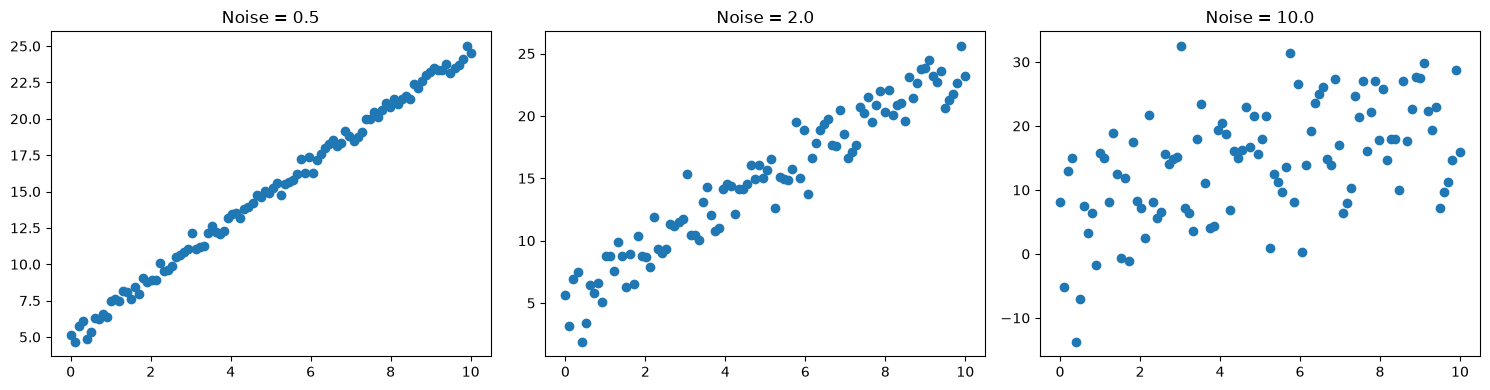

Noise 0.5: 1.9790235816481379
Noise 2.0: 1.916094326592552
Noise 10.0: 1.5804716329627566
Estimated slope: 2.0125637488948644


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(x1, y1)
axes[0].set_title("Noise = 0.5")

axes[1].scatter(x2, y2)
axes[1].set_title("Noise = 2.0")

axes[2].scatter(x3, y3)
axes[2].set_title("Noise = 10.0")

plt.tight_layout()
plt.show()


slope1, intercept1 = np.polyfit(x1, y1, 1)
slope2, intercept2 = np.polyfit(x2, y2, 1)
slope3, intercept3 = np.polyfit(x3, y3, 1)

print("Noise 0.5:", slope1)
print("Noise 2.0:", slope2)
print("Noise 10.0:", slope3)


x_big, y_big = make_line(10_000, 2, 5, 10, seed=42)
slope_big, intercept_big = np.polyfit(x_big, y_big, 1)
print("Estimated slope:", slope_big)

In [62]:
def make_clusters(n, centres, spread, seed=0):

    rng = np.random.default_rng(seed)
    
centres = np.array([[2, 2], [8, 8]])

print("Centres:")
print(centres)

print("Shape:", centres.shape)
print("Number of centres:", len(centres))

print("Original:")
print(centres)
print("Original shape:", centres.shape)

expanded = centres[:, np.newaxis, :]

print("\nExpanded:")
print(expanded)
print("Expanded shape:", expanded.shape)


points = rng.normal(
    loc=centres[:, np.newaxis, :],
    scale=0.5,
    size=(2, 100, 2)
)

print("Points shape:", points.shape)
print("\nFirst cluster, first 5 points:")
print(points[0, :5])

print("\nSecond cluster, first 5 points:")
print(points[1, :5])

points_2d = points.reshape(-1, 2)

print("New shape:", points_2d.shape)
print(points_2d[:5])

labels = np.repeat(np.arange(len(centres)), 100)

print(labels)
print("Labels shape:", labels.shape)
print("First 5 labels:", labels[:5])
print("Last 5 labels:", labels[-5:])

Centres:
[[2 2]
 [8 8]]
Shape: (2, 2)
Number of centres: 2
Original:
[[2 2]
 [8 8]]
Original shape: (2, 2)

Expanded:
[[[2 2]]

 [[8 8]]]
Expanded shape: (2, 1, 2)
Points shape: (2, 100, 2)

First cluster, first 5 points:
[[2.95145373 1.77328085]
 [2.12990393 2.51246085]
 [1.91802325 1.70951991]
 [0.8621318  2.32049536]
 [1.9434158  1.49365807]]

Second cluster, first 5 points:
[[7.41954402 8.01618505]
 [8.07366117 7.76508175]
 [8.21772917 7.60978327]
 [8.25491035 8.27592939]
 [6.54142006 8.59515285]]
New shape: (200, 2)
[[2.95145373 1.77328085]
 [2.12990393 2.51246085]
 [1.91802325 1.70951991]
 [0.8621318  2.32049536]
 [1.9434158  1.49365807]]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 

In [63]:
def make_clusters(n, centres, spread, seed=0):

    rng = np.random.default_rng(seed)

    centres = np.asarray(centres)

    points = rng.normal(
        loc=centres[:, np.newaxis, :],
        scale=spread,
        size=(len(centres), n, 2)
    )

    points = points.reshape(-1, 2)

    labels = np.repeat(np.arange(len(centres)), n)

    return points, labels


points, labels = make_clusters(
    n=100,
    centres=[[2, 2], [8, 8]],
    spread=0.5,
    seed=42
)

print("Points shape:", points.shape)
print("Labels shape:", labels.shape)

Points shape: (200, 2)
Labels shape: (200,)


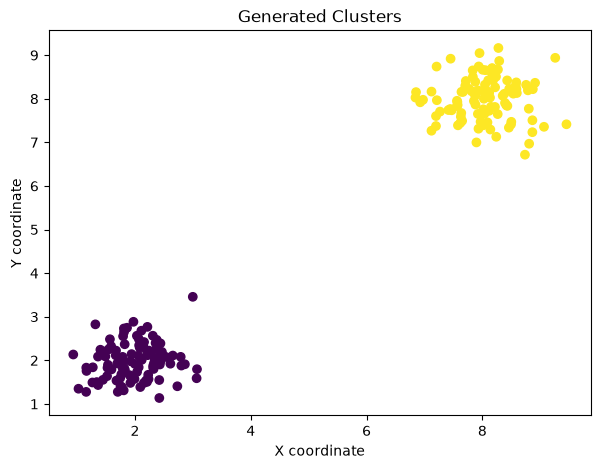

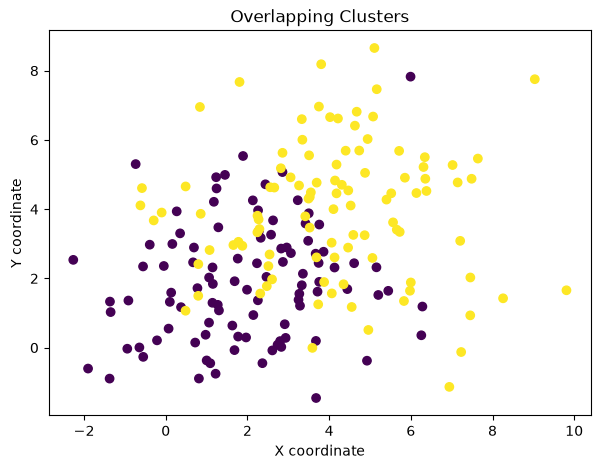

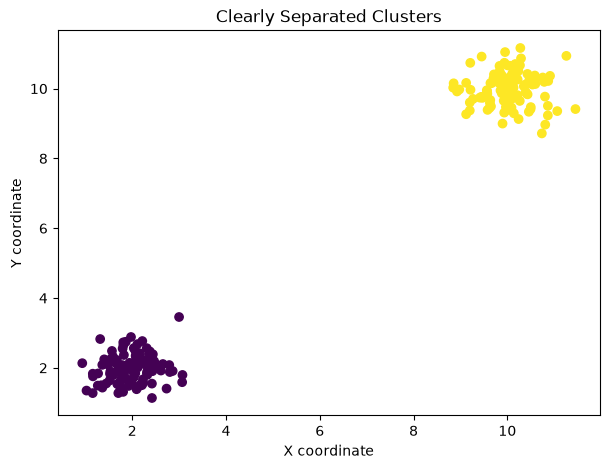

True
True


In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(
    points[:, 0],
    points[:, 1],
    c=labels,
    cmap="viridis"
)

plt.title("Generated Clusters")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.show()




overlap_points, overlap_labels = make_clusters(
    n=100,
    centres=[[2, 2], [4, 4]],
    spread=2.0,
    seed=42
)

plt.figure(figsize=(7, 5))

plt.scatter(
    overlap_points[:, 0],
    overlap_points[:, 1],
    c=overlap_labels,
    cmap="viridis"
)

plt.title("Overlapping Clusters")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.show()




separate_points, separate_labels = make_clusters(
    n=100,
    centres=[[2, 2], [10, 10]],
    spread=0.5,
    seed=42
)

plt.figure(figsize=(7, 5))

plt.scatter(
    separate_points[:, 0],
    separate_points[:, 1],
    c=separate_labels,
    cmap="viridis"
)

plt.title("Clearly Separated Clusters")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.show()


points_a, labels_a = make_clusters(
    100, [[2, 2], [8, 8]], 0.5, seed=42
)

points_b, labels_b = make_clusters(
    100, [[2, 2], [8, 8]], 0.5, seed=42
)

print(np.array_equal(points_a, points_b))
print(np.array_equal(labels_a, labels_b))